In [272]:
# steps to figuring this out
# 1. write whatever stupid functions im able to
# 2. note down all stuff that dont make sense
# 3. look them up and try to understand them
# 4. fix them and try own implementation again
# 5. repeat until something at least runs
# 6. investiage why results don't match
# 7. attempt to enhance and tune (fix)
# 8. check out cSNN impelemtation to see what was actually done differently

In [273]:
import numpy as np
import torch
import matplotlib.pyplot as plt

### simulate single cLIF neuron

In [274]:
def ReLU(x):
    return np.max(a=(0, x))

In [275]:
def apical_comp(a_mem, a_curr, alpha, R_m):

    a_mem = alpha*a_mem + (1-alpha)*(R_m*a_curr)

    return a_mem


def mult_cLIF(mem, a_mem, curr, beta, R_m, threshold):

    print("============")
    print("for curr ", curr)
    print("mem from previous ", mem)
    print("a_mem ", a_mem)
    print("full curr ", (1-beta)*R_m*curr)

    spk = int(mem>=threshold)

    print("spike")

    mem = beta*mem + (1-beta)*(R_m * curr * ReLU(a_mem)) - threshold*spk


    print("new mem ", mem)

    return spk, mem

In [276]:
def generate_rand_spikes(size, spk_frq):

    spikes = (np.random.random(size) <= spk_frq).astype(int)

    return spikes

In [277]:
count = 100
spk_frequency = 0.5

spikes = generate_rand_spikes(count, spk_frequency)

print("spike ratio ", np.sum(spikes)/count)

spike ratio  0.49


In [278]:
# constants
threshold = 25.5

dt = 0.001

R_m = 220e5
C_m = 170e-12
tau = R_m*C_m

curr_scalar = 0.000002

alpha = np.exp(-dt/tau)
beta = np.exp(-dt/tau)

print(alpha)
print(beta)

time = np.arange(100)

mem = 0
a_mem = 0

a_curr = generate_rand_spikes(len(time), 0.1)
curr = generate_rand_spikes(len(time), 0.1)

a_curr = a_curr*curr_scalar
curr = curr*curr_scalar

mem_arr = []
a_mem_arr = []
spk_arr = []

for t in time:

    a_mem = apical_comp(a_mem, a_curr[t], alpha, R_m)

    spk, mem = mult_cLIF(mem, a_mem, curr[t], beta, R_m, threshold)

    mem_arr.append(mem)
    a_mem_arr.append(a_mem)
    spk_arr.append(spk)

0.7653824165500177
0.7653824165500177
for curr  0.0
mem from previous  0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  2e-06
mem from previous  0.0
a_mem  0.0
full curr  10.32317367179922
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.0
full curr  0.0
spike
new mem  0.0
for curr  0.0
mem from previous  0.0
a_mem  0.

/tmp/ipykernel_65772/904431816.py:37: UserWarning: tight_layout not applied: number of rows in subplot specifications must be multiples of one another.
  plt.tight_layout()


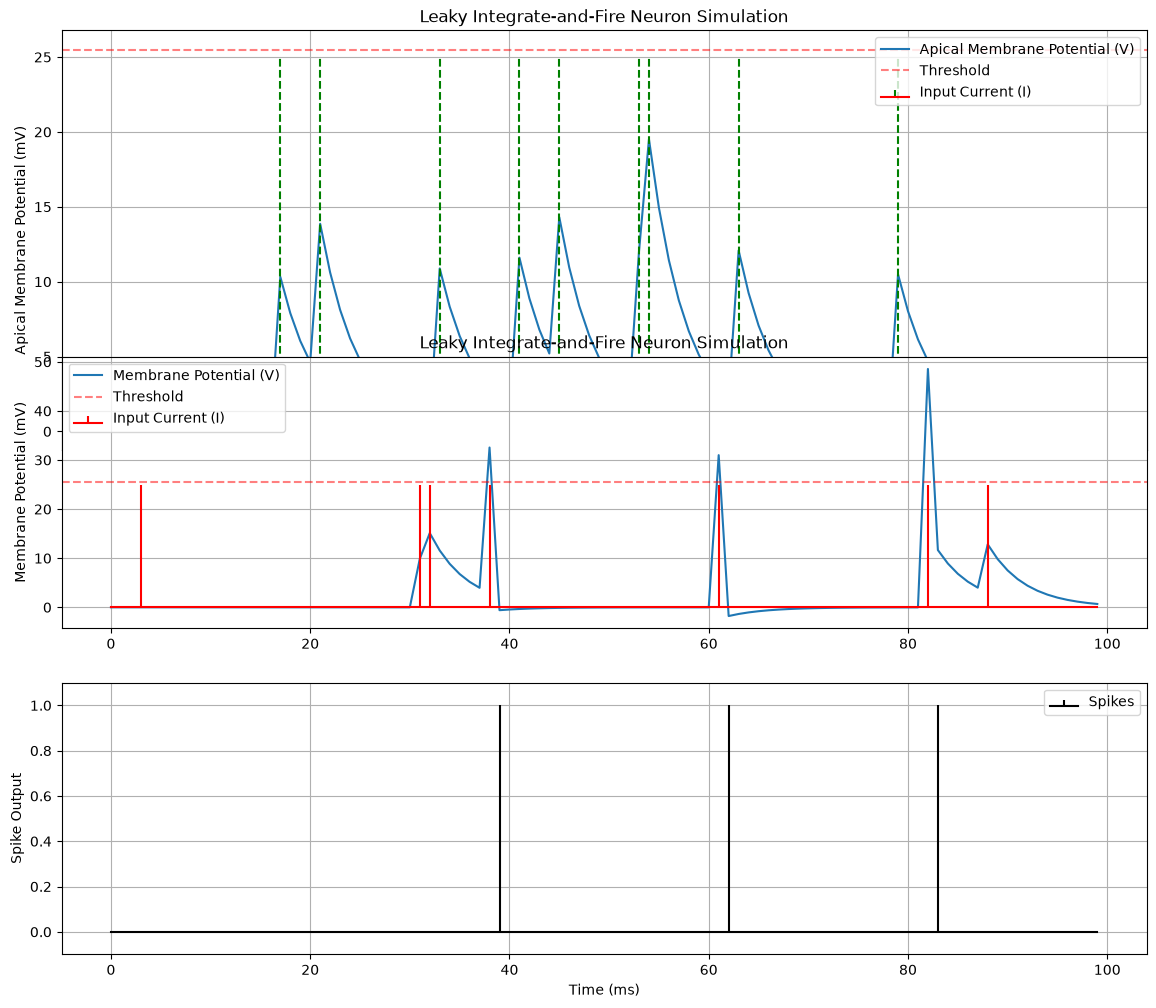

In [281]:
# plot
plt.figure(figsize=(14, 12))

plt.subplot(2, 1, 1)
plt.plot(time[:], a_mem_arr, label='Apical Membrane Potential (V)')
plt.axhline(y=threshold, color='r', linestyle='--', alpha=0.5, label='Threshold')
plt.title('Leaky Integrate-and-Fire Neuron Simulation')
plt.ylabel('Apical Membrane Potential (mV)')


plt.subplot(2, 1, 1)
plt.stem(time[:], a_curr*25*1e6/2, linefmt='g--', markerfmt=' ', basefmt='r-', label='Input Current (I)')
plt.legend()
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(time[:], mem_arr, label='Membrane Potential (V)')
plt.axhline(y=threshold, color='r', linestyle='--', alpha=0.5, label='Threshold')
plt.title('Leaky Integrate-and-Fire Neuron Simulation')
plt.ylabel('Membrane Potential (mV)')
plt.legend()

plt.subplot(3, 1, 2)
plt.stem(time[:], curr*25*1e6/2, linefmt='r-', markerfmt=' ', basefmt='r-', label='Input Current (I)')
plt.legend()
plt.grid()

plt.subplot(3, 1, 3)
#plt.plot(time[:], spk_rec, 'r', linewidth=2, label='Spikes')
plt.stem(time[:], spk_arr, linefmt='k-', markerfmt=' ', basefmt='k-', label='Spikes')
plt.ylabel('Spike Output')
plt.xlabel('Time (ms)')
plt.ylim([-0.1, 1.1])
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

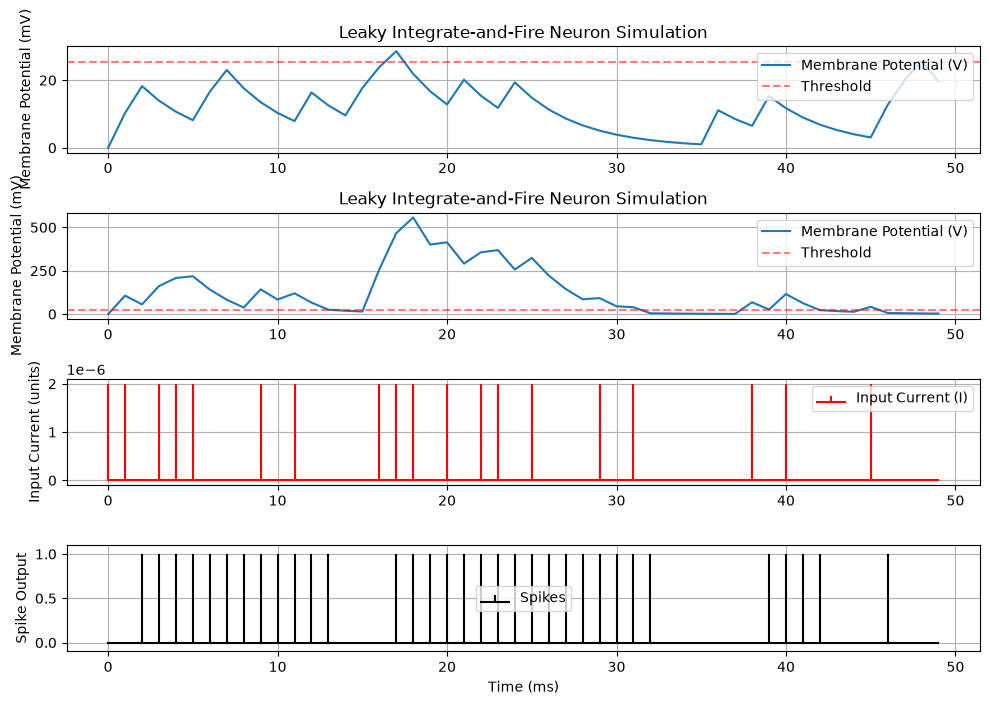

In [244]:
# plot
plt.figure(figsize=(10, 7))

plt.subplot(4, 1, 1)
plt.plot(time[:], a_mem_arr, label='Membrane Potential (V)')
plt.axhline(y=threshold, color='r', linestyle='--', alpha=0.5, label='Threshold')
plt.title('Leaky Integrate-and-Fire Neuron Simulation')
plt.ylabel('Membrane Potential (mV)')
plt.legend()
plt.grid()

plt.subplot(4, 1, 2)
plt.plot(time[:], mem_arr, label='Membrane Potential (V)')
plt.axhline(y=threshold, color='r', linestyle='--', alpha=0.5, label='Threshold')
plt.title('Leaky Integrate-and-Fire Neuron Simulation')
plt.ylabel('Membrane Potential (mV)')
plt.legend()
plt.grid()

plt.subplot(4, 1, 3)
plt.stem(time[:], curr, linefmt='r-', markerfmt=' ', basefmt='r-', label='Input Current (I)')
plt.ylabel('Input Current (units)')
plt.legend()
plt.grid()

plt.subplot(4, 1, 4)
#plt.plot(time[:], spk_rec, 'r', linewidth=2, label='Spikes')
plt.stem(time[:], spk_arr, linefmt='k-', markerfmt=' ', basefmt='k-', label='Spikes')
plt.ylabel('Spike Output')
plt.xlabel('Time (ms)')
plt.ylim([-0.1, 1.1])
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()
